# 04 — Definición de KPIs

Fase 4 del proyecto. Aquí definimos y calculamos los indicadores clave, los justificamos desde el negocio, los relacionamos con las hipótesis e interpretamos cada uno. Los valores sirven de referencia para verificar las medidas del dashboard.

## 1. Definición de KPIs

Definimos seis indicadores para apoyar las decisiones de una productora con capital limitado: cuánto invertir, cuándo estrenar y qué tipo de película hacer. Cubrimos el retorno habitual, la proporción que alcanza el umbral acordado, la exposición a no recuperar el presupuesto, el capital requerido y el volumen de taquilla. Para comparar temporadas conservamos también la medida utilizada en la prueba estadística.

Cada ficha establece nombre, fórmula, población, unidad, justificación de negocio, relación con las hipótesis e interpretación. Aquí dejamos el contrato de cálculo; los valores generales, las comparaciones por segmento y la tabla de referencia para Power BI se desarrollarán en la siguiente sección de este notebook.

Usamos las definiciones del notebook 02 y las pruebas del notebook 03. Cuando mencionamos H1 hablamos de presupuesto y retorno; H2 corresponde a temporada de estreno y H3 a género y rentabilidad. Un KPI resume el desempeño observado: su valor, por sí solo, no demuestra una causa ni sustituye la prueba estadística.

### 1.1 Entrada y comprobación de las variables disponibles

Leemos `data/processed/peliculas_variables.csv`, el resultado de preparación y selección de variables. No dependemos de ejecutar los notebooks anteriores en el mismo kernel. Las rutas funcionan desde `notebooks/` o desde la raíz del repositorio.

La lectura explícita de lógicos con faltantes conserva la diferencia entre `rentable = False` y una película cuya rentabilidad no se puede evaluar. No cambiamos la limpieza ni recalculamos los filtros acordados.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display, Markdown

kpi_ruta = next((carpeta / "data/processed/peliculas_variables.csv"
                 for carpeta in (Path.cwd(), Path.cwd().parent)
                 if (carpeta / "data/processed/peliculas_variables.csv").is_file()), None)
if kpi_ruta is None:
    raise FileNotFoundError(
        "Necesitamos data/processed/peliculas_variables.csv. "
        "Ejecutamos desde notebooks/ o desde la raíz del proyecto."
    )

kpi_peliculas = pd.read_csv(
    kpi_ruta, parse_dates=["release_date"],
    dtype={"anio": "Int64", "mes": "Int64", "decada": "Int64",
           "temporada_alta": "boolean", "rentable": "boolean",
           "estrenada": "boolean", "monto_dudoso": "boolean", "base_financiera": "boolean"},
)
kpi_columnas_requeridas = {
    "id", "release_date", "anio", "mes", "decada", "temporada_alta", "original_language",
    "genero_principal", "genero_agrupado", "budget", "revenue", "roi", "multiplicador",
    "rentable", "estrenada", "monto_dudoso", "base_financiera",
}
assert kpi_columnas_requeridas.issubset(kpi_peliculas.columns), "Faltan variables para los indicadores"
assert kpi_peliculas["id"].notna().all() and kpi_peliculas["id"].is_unique
assert kpi_peliculas[["estrenada", "monto_dudoso", "base_financiera"]].notna().all().all()
kpi_base = kpi_peliculas.loc[kpi_peliculas["base_financiera"]].copy()
assert not kpi_base.empty, "No hay películas elegibles para verificar las definiciones financieras"

display(pd.Series({
    "Películas del archivo": len(kpi_peliculas),
    "Población financiera disponible": len(kpi_base),
    "De la población financiera, desde 2000": int(kpi_base["anio"].ge(2000).sum()),
    "De la población financiera, sin género agrupado": int(kpi_base["genero_agrupado"].isna().sum()),
}, name="películas").to_frame())

,películas
Películas del archivo,4803
Población financiera disponible,3204
"De la población financiera, desde 2000",2265
"De la población financiera, sin género agrupado",1


### 1.2 Población y reglas comunes

Llamamos **F** al conjunto de películas con `base_financiera = True`: estrenadas, con presupuesto y recaudación reportados y sin montos menores a USD 10.000, según la preparación existente. Para un filtro o segmento **S** usamos **Fₛ = F ∩ S** y **nₛ** es su número de películas únicas. Los seis indicadores comparten ese conjunto, incluso presupuesto y recaudación, para comparar retorno y volumen sobre las mismas películas.

En el archivo actual hay 3.204 películas elegibles. Esa cantidad es una comprobación de entrada, no un denominador fijo: al filtrar por género, década, idioma o temporada, el denominador debe recalcularse dentro de Fₛ.

- **Una película, una observación.** Contamos `id` únicos. Al usar el modelo dimensional, el equivalente es `fact_peliculas.pelicula_id`; los puentes solo seleccionan películas, no replican sus importes.
- **Sin población válida, sin valor.** Si nₛ = 0, los seis indicadores se presentan como no disponibles (`NaN` en Python o blanco en Power BI). Una taquilla de cero o un 0 % comunicarían un resultado que no observamos. En la suma usamos `sum(min_count=1)` después de seleccionar la población.
- **Retorno registrado como razón.** `roi = multiplicador - 1` se conserva en escala decimal. Para mostrarlo en Python como porcentaje multiplicamos por 100 una sola vez. En Power BI puede conservarse la fracción y aplicarse formato de porcentaje; no se combina ese formato con otra multiplicación por 100. Lo mismo vale para las dos proporciones.
- **Cortes consistentes.** `multiplicador < 1` significa que la taquilla no recuperó el presupuesto; `multiplicador >= 2` es el criterio aproximado de rentable. Los casos con multiplicador igual a 1 no entran al primer grupo, y los iguales a 2 sí entran al segundo. Entre 1 y menos de 2 existe un grupo intermedio.
- **Montos nominales.** Presupuesto y recaudación se expresan en USD de la época, sin ajuste por inflación. Estos indicadores no miden utilidad neta, porque faltan publicidad, participación de salas y otros costos e ingresos.

Antes de continuar verificamos que las variables disponibles cumplan esas definiciones. Son controles sobre las columnas existentes; todavía no calculamos los valores de los seis KPIs.

In [2]:
kpi_umbral_rentable = 2
kpi_monto_minimo = 10_000
kpi_meses_temporada_alta = [5, 6, 7, 8, 11, 12]

assert kpi_base[["budget", "revenue", "roi", "multiplicador", "rentable"]].notna().all().all()
assert np.isfinite(kpi_base[["budget", "revenue", "roi", "multiplicador"]]).all().all()
assert kpi_base[["budget", "revenue"]].ge(kpi_monto_minimo).all().all()
assert kpi_base["estrenada"].all() and not kpi_base["monto_dudoso"].any()
assert kpi_base["multiplicador"].gt(0).all(), "El logaritmo necesita multiplicadores positivos"
assert np.allclose(kpi_base["multiplicador"], kpi_base["revenue"] / kpi_base["budget"])
assert np.allclose(kpi_base["roi"], kpi_base["multiplicador"] - 1)
assert kpi_base["rentable"].eq(kpi_base["multiplicador"].ge(kpi_umbral_rentable)).all()

kpi_con_fecha = kpi_base["release_date"].notna()
assert kpi_base["temporada_alta"].isna().eq(kpi_base["release_date"].isna()).all()
assert kpi_base.loc[kpi_con_fecha, "temporada_alta"].eq(
    kpi_base.loc[kpi_con_fecha, "mes"].isin(kpi_meses_temporada_alta)).all()
print("Entrada verificada: identidad, población financiera, razones y umbrales consistentes.")

Entrada verificada: identidad, población financiera, razones y umbrales consistentes.


### 1.3 Catálogo de los seis indicadores

Registramos identificadores estables para referirnos a los mismos KPIs en el cálculo y en el dashboard. La columna `expresion_python` es una referencia de implementación sobre una tabla `base` que ya representa Fₛ; se guarda como texto y no se evalúa en esta sección. Antes de usar cualquier expresión se comprueba que el grupo no esté vacío.

Las fórmulas, la interpretación y las limitaciones se detallan en las fichas siguientes. La vinculación con una hipótesis indica qué pregunta ayuda a seguir el indicador; no implica que todas las diferencias de ese KPI hayan sido sometidas a una prueba específica.

In [3]:
kpi_definiciones = [
    {"id": "KPI01", "nombre": "ROI mediano", "unidad": "%",
     "hipotesis": "H1", "columnas": ["roi"],
     "expresion_python": '100 * base["roi"].median()'},
    {"id": "KPI02", "nombre": "Películas rentables según umbral 2x", "unidad": "%",
     "hipotesis": "H3", "columnas": ["rentable", "multiplicador"],
     "expresion_python": '100 * base["rentable"].mean()'},
    {"id": "KPI03", "nombre": "Películas que no recuperan el presupuesto", "unidad": "%",
     "hipotesis": "H1, H2", "columnas": ["multiplicador"],
     "expresion_python": '100 * base["multiplicador"].lt(1).mean()'},
    {"id": "KPI04", "nombre": "Presupuesto mediano", "unidad": "USD",
     "hipotesis": "H1", "columnas": ["budget"],
     "expresion_python": 'base["budget"].median()'},
    {"id": "KPI05", "nombre": "Recaudación total", "unidad": "USD",
     "hipotesis": "H1", "columnas": ["revenue"],
     "expresion_python": 'base["revenue"].sum(min_count=1)'},
    {"id": "KPI06", "nombre": "Multiplicador típico (media geométrica)", "unidad": "veces (x)",
     "hipotesis": "H2", "columnas": ["multiplicador"],
     "expresion_python": '10 ** np.log10(base["multiplicador"]).mean()'},
]
kpi_catalogo = pd.DataFrame(kpi_definiciones).set_index("id")
with pd.option_context("display.max_colwidth", 55):
    display(kpi_catalogo[["nombre", "unidad", "hipotesis"]])

,nombre,unidad,hipotesis
id,,,
KPI01,ROI mediano,%,H1
KPI02,Películas rentables según umbral 2x,%,H3
KPI03,Películas que no recuperan el presupuesto,%,"H1, H2"
KPI04,Presupuesto mediano,USD,H1
KPI05,Recaudación total,USD,H1
KPI06,Multiplicador típico (media geométrica),veces (x),H2


### 1.4 KPI01 — ROI mediano

**Fórmula.** Para cada película i de Fₛ definimos Rᵢ = revenueᵢ / budgetᵢ. El indicador es:

$$\text{ROI mediano}_s = 100 \times \operatorname{mediana}_{i \in F_s}(R_i - 1)$$

**Población y unidad.** Películas únicas de Fₛ; porcentaje. Usamos el `roi` ya calculado, que está en escala decimal.

**Justificación de negocio.** Describe el retorno central de las películas comparables sin dejar que unas pocas producciones con multiplicadores enormes dominen un promedio. Ayuda a contrastar cuánto rinde cada dólar con cuánto capital exige un segmento.

**Relación con H1.** La hipótesis 1 estudia presupuesto frente a multiplicador; restar uno no cambia sus rangos. Este KPI permite seguir el retorno por nivel de presupuesto y época, pero no sustituye el coeficiente ni el valor p. El resultado de H1 cambió al controlar por época, por lo que debemos mostrar también la vista desde 2000.

**Cómo lo interpretamos.** Un ROI individual de 0 % significa recaudar lo mismo que el presupuesto; 100 % equivale a un multiplicador de 2x. El KPI resume la mediana de esos retornos, no el porcentaje de películas rentables ni el retorno conjunto de una cartera. Un valor más alto indica mayor retorno central observado, sujeto a la composición del grupo y al criterio de datos válidos.

**Límite.** No lo calculamos como `(sum(revenue) - sum(budget)) / sum(budget)`: esa sería otra medida, ponderada por el tamaño de las inversiones. Tampoco es utilidad neta para la productora.

### 1.5 KPI02 — Porcentaje de películas rentables según el umbral de 2x

**Fórmula.** Usamos la condición `rentable` acordada en la preparación:

$$\text{Rentables}_s = 100 \times \frac{\#\{i \in F_s : R_i \geq 2\}}{n_s}$$

**Población y unidad.** Todas las películas únicas de Fₛ; porcentaje. El denominador incluye también las que no alcanzaron 2x, pero no las películas fuera de la base financiera, cuyo `rentable` está vacío.

**Justificación de negocio.** Mide con qué frecuencia histórica un grupo alcanzó la regla de retorno definida por el equipo. Ayuda a comparar opciones de contenido y a distinguir un segmento con éxitos excepcionales de otro que alcanza el umbral con mayor frecuencia.

**Relación con H3.** Es la proporción que compara la prueba de género y rentabilidad. Para reproducir esa comparación usamos `genero_agrupado`, con los mismos grupos de la hipótesis 3. La asociación observada no convierte el porcentaje histórico en una probabilidad garantizada para la próxima película.

**Cómo lo interpretamos.** Un porcentaje mayor significa que más películas del grupo recaudaron al menos el doble de su presupuesto. Las diferencias entre porcentajes se comunican en **puntos porcentuales**; no confundimos esa diferencia con un cambio porcentual relativo.

**Límite.** El umbral 2x es una aproximación del proyecto, no una medición exacta del punto de equilibrio. No inventamos una meta de 50 %, 60 % u otro valor que la productora no haya definido. En grupos sin observaciones el resultado queda no disponible.

### 1.6 KPI03 — Porcentaje de películas que no recuperan el presupuesto en taquilla

**Fórmula.** Contamos las películas cuya recaudación es menor que su presupuesto:

$$\text{No recuperan presupuesto}_s = 100 \times \frac{\#\{i \in F_s : R_i < 1\}}{n_s}$$

**Población y unidad.** Películas únicas de Fₛ; porcentaje. Igual que en KPI02, el denominador se recalcula en cada grupo.

**Justificación de negocio.** Una productora con capital limitado necesita vigilar el riesgo de que la taquilla ni siquiera cubra el presupuesto reportado, además del retorno central. Un ROI mediano favorable puede coexistir con una proporción relevante de resultados por debajo de 1x.

**Relación con H1 y H2.** Las secciones de magnitud del notebook 03 comparan este riesgo por presupuesto y temporada. Esas proporciones se estudiaron de manera descriptiva: los valores p de Spearman y Welch no constituyen pruebas específicas de diferencias de este porcentaje.

**Cómo lo interpretamos.** Un valor menor indica menos películas que quedaron por debajo del presupuesto en la taquilla registrada. No lo llamamos porcentaje de quiebras ni de pérdidas contables: no conocemos el conjunto de costos e ingresos del productor.

**Límite.** No es `100 - KPI02`. Las películas con 1x ≤ Rᵢ < 2x no pertenecen a ninguno de esos dos numeradores. Con Rᵢ = 1 no marcamos falta de recuperación del presupuesto; con Rᵢ = 2 sí marcamos rentable según la regla del proyecto.

### 1.7 KPI04 — Presupuesto mediano

**Fórmula.**

$$\text{Presupuesto mediano}_s = \operatorname{mediana}_{i \in F_s}(budget_i)$$

**Población y unidad.** Películas únicas de Fₛ; USD nominales. Si lo presentamos en millones, dividimos el resultado entre un millón y dejamos visible la unidad.

**Justificación de negocio.** Describe el capital de producción habitual de las películas que estamos comparando y ayuda a evaluar si una estrategia es compatible con una productora de recursos limitados. Elegimos la mediana por la asimetría de los presupuestos observada en el diagnóstico y las hipótesis.

**Relación con H1.** Es el contexto de inversión para el retorno. La hipótesis 1 distingue gastar más de rendir más por dólar, y su control por época evita atribuir al presupuesto una relación que puede venir de mezclar periodos.

**Cómo lo interpretamos.** Un valor alto describe producciones con una escala de inversión mayor; uno bajo describe menor requerimiento central de capital. Ninguna dirección es mejor por sí sola: lo leemos junto con ROI mediano, proporción rentable y riesgo. No conocemos el capital de la productora para fijar una meta numérica de presupuesto.

**Límite.** No representa el presupuesto total necesario para financiar todas las películas de un grupo. Al comparar décadas recordamos que no ajustamos los USD por inflación.

### 1.8 KPI05 — Recaudación total

**Fórmula.**

$$\text{Recaudación total}_s = \sum_{i \in F_s} revenue_i$$

**Población y unidad.** Películas únicas de Fₛ; USD nominales. Conservamos exactamente la población financiera usada por los otros cinco indicadores. No mezclamos una taquilla calculada con todas las películas que reportaron `revenue` con un retorno calculado sobre una población menor.

**Justificación de negocio.** Muestra el volumen de taquilla observado en el segmento y aporta contexto sobre la escala comercial. Debe acompañarse de nₛ, porque un grupo con más películas puede recaudar más solo por su tamaño.

**Relación con H1.** Ayuda a distinguir el dinero recaudado del rendimiento por cada dólar invertido, que es la pregunta de la hipótesis. Una recaudación mayor no demuestra un ROI mayor ni confirma una relación causal con el presupuesto.

**Cómo lo interpretamos.** Un total mayor indica más taquilla agregada dentro del filtro y de la población declarada. Se puede expresar en millones, con unidad visible. No lo interpretamos como ganancia, ingreso neto de la productora ni tamaño de todo el mercado cinematográfico.

**Límite.** El total general se obtiene de las películas únicas. No sumamos subtotales de géneros multivaluados o directores para reconstruirlo, porque una película puede aparecer en varios segmentos. En grupos vacíos la suma debe quedar no disponible, no en cero.

### 1.9 KPI06 — Multiplicador típico: media geométrica

**Fórmula.** Devolvemos a la escala original el promedio del logaritmo del multiplicador:

$$G_s = 10^{\frac{1}{n_s}\sum_{i \in F_s}\log_{10}(R_i)}$$

**Población y unidad.** Películas únicas de Fₛ, con multiplicadores positivos; veces (x). La población financiera ya cumple esa condición. La media geométrica fue introducida en la sección 2.2 del notebook 03 como lectura de negocio de la prueba de temporada; no es un concepto desarrollado en las guías de clase.

**Justificación de negocio.** Permite seguir la misma medida de retorno que se comparó estadísticamente entre temporada alta y resto del año. Así evitamos presentar una mediana o un promedio aritmético como si fueran el resultado de la prueba sobre promedios de logaritmos.

**Relación con H2.** Si calculamos G_alta y G_resto sobre la misma población y periodo, su cociente es `10 ** (media_log_alta - media_log_resto)`, la escala de comparación usada por Welch. Se mantienen los meses de temporada alta y el control desde 2000 del notebook 03.

**Cómo lo interpretamos.** Describe el centro multiplicativo del retorno observado. Un Gₛ mayor representa mayor retorno en esa escala, pero no indica la fracción de rentables. Un cociente G_alta / G_resto mayor que 1 señala ventaja descriptiva de temporada alta, y un cociente igual a 1 indica igualdad de esta medida; la incertidumbre se lee con la prueba y su intervalo correspondientes.

**Límite.** No es la mediana ni `sum(revenue) / sum(budget)`. Para un total o un nuevo segmento se recalcula con las películas originales; no promediamos las medias geométricas de grupos ni extrapolamos el valor p de toda la base a cada filtro del dashboard.

### 1.10 Reglas de segmentación, comparación y presentación

| Vista | Variable preparada | Regla de lectura |
|---|---|---|
| Género y comparación con H3 | `genero_agrupado` | Mantener los grupos de la prueba; informar las películas sin género. |
| Género principal descriptivo | `genero_principal` | Una categoría por película; declarar que se toma la primera de la fuente. |
| Todos los géneros | Puente `pelicula_genero` | Seleccionar identificadores únicos antes de calcular; los grupos se solapan. |
| Década y control de época | `decada`, `anio` | Mostrar toda la base y la vista desde 2000 sin reemplazar una por otra; la década de 2010 está incompleta. |
| Idioma original | `original_language` | Informar nₛ; los grupos pequeños y el predominio del inglés limitan la comparación. |
| Temporada de estreno | `temporada_alta` | Mayo–agosto y noviembre–diciembre; comparar grupos en el mismo periodo. |
| Talento en el modelo | Puente `pelicula_director` | Seleccionar películas únicas aunque tengan varios directores. |

La base financiera contiene una película sin género agrupado. Se incluye en los indicadores generales, pero la prueba de H3 la excluye. Para reproducir esa prueba se declara esa exclusión; si una vista descriptiva quiere mantener cobertura completa, puede mostrarla como **sin género registrado** sin modificar el archivo preparado ni añadirla a la prueba original. La misma regla de declarar faltantes se aplica a cualquier dimensión de segmentación.

Cada resultado debe mostrar el periodo o filtro, nₛ y la unidad. Las medianas y proporciones se recalculan desde las películas al cambiar el filtro: no promediamos los porcentajes o las medianas de los segmentos para obtener el total. Recaudación sí se suma sobre conjuntos sin solapamiento. Las diferencias entre porcentajes se expresan en puntos porcentuales y los cocientes de multiplicadores en veces.

Los umbrales 1x y 2x tienen significados definidos, pero no contamos con metas de la productora para asignar semáforos de desempeño. Las comparaciones históricas no eliminan el sesgo de selección de películas con cifras, ni convierten asociación en causalidad. Un segmento con pocos casos debe informar su soporte y no se presenta como evidencia concluyente.

### 1.11 Comprobación del catálogo y continuidad del cálculo

Dejamos seis fichas con fórmulas, población y forma de interpretación; el catálogo relaciona cada una con las variables y las hipótesis ya implementadas. La siguiente sección podrá usar `kpi_base`, seleccionar Fₛ y aplicar las expresiones definidas, comprobando primero si el grupo está vacío.

El cálculo posterior deberá presentar los valores generales y por género, década e idioma, y conservar la comparación por temporada y época cuando corresponda. Su tabla de referencia indicará los filtros y nₛ para contrastar después las medidas de Power BI. Aquí verificamos la disponibilidad y coherencia de las entradas y la integridad del catálogo, sin exportar ni modificar los datos preparados.

In [4]:
assert len(kpi_catalogo) >= 5
assert kpi_catalogo.index.is_unique and kpi_catalogo["nombre"].is_unique
assert kpi_catalogo[["nombre", "unidad", "hipotesis", "expresion_python"]].notna().all().all()
assert kpi_catalogo["unidad"].isin(["%", "USD", "veces (x)"]).all()
kpi_hipotesis_cubiertas = set()
for kpi_definicion in kpi_definiciones:
    assert set(kpi_definicion["columnas"]).issubset(kpi_base.columns)
    kpi_hipotesis_cubiertas.update(kpi_definicion["hipotesis"].split(", "))
assert kpi_hipotesis_cubiertas == {"H1", "H2", "H3"}
print(f"Definición terminada: {len(kpi_catalogo)} KPIs con variables verificadas "
      "y relación con las tres hipótesis. Fórmulas listas para el cálculo posterior.")

Definición terminada: 6 KPIs con variables verificadas y relación con las tres hipótesis. Fórmulas listas para el cálculo posterior.


## 2. Cálculo e interpretación de los KPIs

En esta sección calculamos los seis KPIs con las fórmulas de la sección 1 y los interpretamos. Empezamos por los valores generales, después los partimos por género, década e idioma, revisamos que coincidan con las pruebas del notebook 03 y terminamos con una tabla de referencia para comprobar las medidas de Power BI.

Siguiendo la sección 1.10, cada resultado lleva su número de películas (nₛ) y su periodo. En casi todas las vistas usamos las películas **desde 2000**, que son la referencia que le sirve hoy a la productora: en el notebook 03 vimos que mezclar épocas cambia los resultados, sobre todo en la hipótesis 1. La vista por década sí usa toda la base, porque justamente compara épocas.

### 2.1 Función de cálculo

Escribimos una sola función que recibe un grupo de películas (Fₛ) y devuelve los seis KPIs. Así todas las vistas usan exactamente las mismas fórmulas. Si el grupo está vacío devuelve `NaN`, como pide la sección 1.2. Antes de usarla comprobamos que da lo mismo que las expresiones del catálogo de la sección 1.3.

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
AZUL, GRIS = "#2b6cb0", "#a0aec0"
kpi_anio_corte = 2000

kpi_columnas = {
    "KPI01": "ROI mediano (%)",
    "KPI02": "% rentables",
    "KPI03": "% no recuperan presupuesto",
    "KPI04": "Presupuesto mediano (M USD)",
    "KPI05": "Recaudación total (M USD)",
    "KPI06": "Multiplicador típico (x)",
}


def kpi_calcular(base):
    # Calcula los seis KPIs sobre un grupo de películas de la base financiera
    n = base["id"].nunique()
    if n == 0:
        return pd.Series({"Películas": 0, **{nombre: np.nan for nombre in kpi_columnas.values()}})
    return pd.Series({
        "Películas": n,
        kpi_columnas["KPI01"]: 100 * base["roi"].median(),
        kpi_columnas["KPI02"]: 100 * base["rentable"].mean(),
        kpi_columnas["KPI03"]: 100 * base["multiplicador"].lt(1).mean(),
        kpi_columnas["KPI04"]: base["budget"].median() / 1e6,
        kpi_columnas["KPI05"]: base["revenue"].sum(min_count=1) / 1e6,
        kpi_columnas["KPI06"]: 10 ** np.log10(base["multiplicador"]).mean(),
    })


def kpi_por_segmento(datos, columna):
    # Calcula los KPIs para cada valor de la columna, recalculando cada grupo desde sus películas
    segmentos = {valor: kpi_calcular(grupo) for valor, grupo in datos.groupby(columna, observed=True)}
    return pd.DataFrame(segmentos).T.astype({"Películas": int})


kpi_desde_2000 = kpi_base[kpi_base["anio"].ge(kpi_anio_corte).fillna(False)]

# Comprobación contra las expresiones del catálogo (KPI04 y KPI05 los mostramos en millones)
kpi_escala = {"KPI04": 1e6, "KPI05": 1e6}
for datos in (kpi_base, kpi_desde_2000):
    calculado = kpi_calcular(datos)
    for kpi_id, fila in kpi_catalogo.iterrows():
        esperado = eval(fila["expresion_python"], {"__builtins__": {}, "np": np}, {"base": datos})
        assert np.isclose(calculado[kpi_columnas[kpi_id]], esperado / kpi_escala.get(kpi_id, 1)), kpi_id
assert kpi_calcular(kpi_base.iloc[0:0]).drop("Películas").isna().all()
print("La función coincide con las seis expresiones del catálogo, y un grupo vacío da NaN.")

La función coincide con las seis expresiones del catálogo, y un grupo vacío da NaN.


### 2.2 Valores generales

Calculamos los seis KPIs sobre toda la base financiera y sobre las películas desde 2000. Estos valores son la **línea base**: un género, una década o una temporada solo es interesante si se aleja de ellos.

In [6]:
kpi_general = pd.DataFrame({
    "Toda la base": kpi_calcular(kpi_base),
    f"Desde {kpi_anio_corte}": kpi_calcular(kpi_desde_2000),
}).T.astype({"Películas": int})
kpi_general.round(2)

,Películas,ROI mediano (%),% rentables,% no recuperan presupuesto,Presupuesto mediano (M USD),Recaudación total (M USD),Multiplicador típico (x)
Toda la base,3204,130.56,56.21,24.19,25.52,391472.08,2.04
Desde 2000,2265,115.30,53.25,25.61,30.00,303605.75,1.81


**¿Qué vemos?** Desde 2000, la película típica de la base recauda un poco más del doble de lo que costó: el ROI mediano es de 115 %. Un poco más de la mitad (53,2 %) llega al umbral de 2x, y una de cada cuatro (25,6 %) ni siquiera recupera su presupuesto en taquilla. El presupuesto mediano es de 30 millones de dólares.

Al comparar con toda la base, todos los indicadores de retorno empeoran desde 2000: el ROI mediano baja de 131 % a 115 %, los rentables de 56,2 % a 53,2 % y el multiplicador típico de 2,04x a 1,81x, mientras que el presupuesto mediano sube de 25,5 a 30 millones. Es el mismo efecto de época del notebook 03: las películas viejas que tienen cifras son sobre todo clásicos exitosos con presupuestos en dólares de otra época. Si la productora tomara como referencia toda la base, esperaría más retorno del que da el cine reciente.

El ROI mediano (115 %, o sea un multiplicador mediano de 2,15x) y el multiplicador típico (1,81x) no dan lo mismo porque miden cosas distintas (sección 1.9). En la hipótesis 2 vimos que el logaritmo del multiplicador tiene la cola hacia la izquierda, donde están los fracasos, y esa cola jala el promedio del logaritmo por debajo de la mediana. Por eso el multiplicador típico es más pesimista que la mediana.

La recaudación total (303.606 millones de dólares desde 2000) es solo contexto: crece con el número de películas y no dice nada del retorno.

### 2.3 KPIs por género (desde 2000)

Usamos `genero_agrupado`, con los mismos 12 grupos de la hipótesis 3, para que los porcentajes se puedan leer junto con la prueba. La película sin género registrado queda por fuera de esta vista, pero sí cuenta en los valores generales (sección 1.10).

En la gráfica cruzamos dos KPIs que a la productora le importan al mismo tiempo: cuánta plata exige el género (presupuesto mediano, KPI04) y con qué frecuencia llega a recaudar el doble de lo que cuesta (% rentables, KPI02). El tamaño de cada punto es el número de películas.

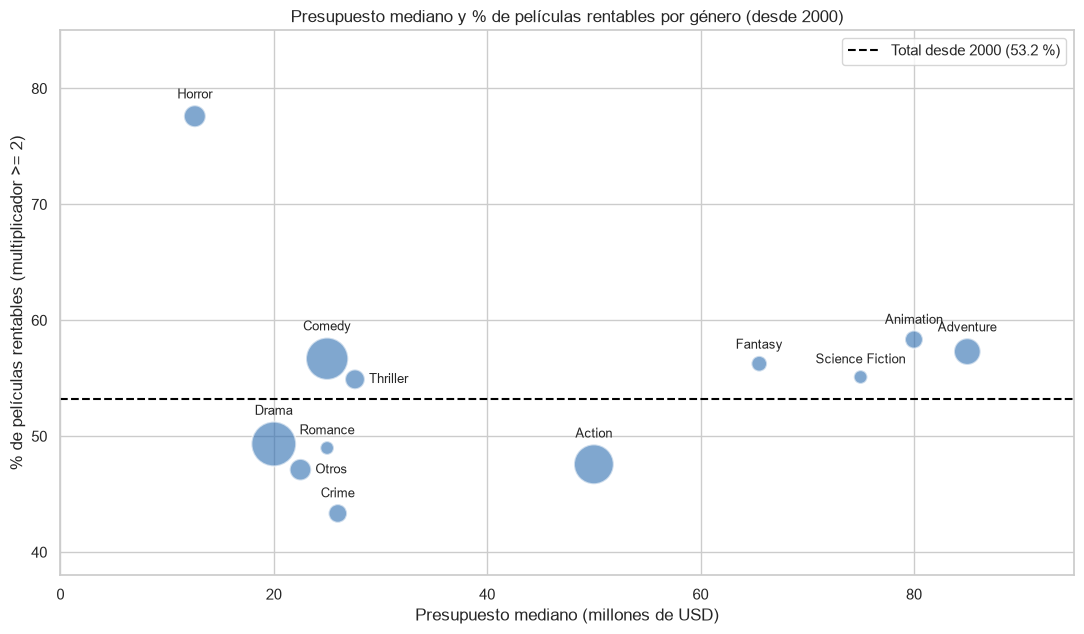

,Películas,ROI mediano (%),% rentables,% no recuperan presupuesto,Presupuesto mediano (M USD),Recaudación total (M USD),Multiplicador típico (x)
Horror,125,249.2,77.6,15.2,12.6,9217.3,3.7
Animation,84,135.3,58.3,19.0,80.0,26506.8,2.1
Adventure,185,123.4,57.3,20.5,85.0,54495.9,1.9
Comedy,464,133.6,56.7,23.9,25.0,40815.5,2.0
Fantasy,64,122.7,56.2,14.1,65.5,13294.2,2.0
Science Fiction,49,157.1,55.1,16.3,75.0,13107.5,2.1
Thriller,102,116.1,54.9,23.5,27.6,10426.3,1.7
Drama,519,92.5,49.3,32.8,20.0,37910.7,1.6
Romance,49,99.2,49.0,22.4,25.0,4018.3,1.7
Action,412,87.9,47.6,25.7,50.0,73240.3,1.6


In [7]:
kpi_genero = (kpi_por_segmento(kpi_desde_2000.dropna(subset=["genero_agrupado"]), "genero_agrupado")
              .sort_values(kpi_columnas["KPI02"], ascending=False))
kpi_linea_base = kpi_general.loc[f"Desde {kpi_anio_corte}"]

fig, ax = plt.subplots(figsize=(11, 6.5))
ax.scatter(kpi_genero[kpi_columnas["KPI04"]], kpi_genero[kpi_columnas["KPI02"]],
           s=kpi_genero["Películas"] * 2, color=AZUL, alpha=0.6, edgecolor="white", linewidth=1.5)
etiquetas_derecha = {"Thriller", "Otros"}  # para que no se monten sobre las burbujas vecinas
for genero, fila in kpi_genero.iterrows():
    # La etiqueta va justo afuera del borde de cada burbuja
    radio = np.sqrt(fila["Películas"] * 2) / 2
    if genero in etiquetas_derecha:
        posicion = {"xytext": (radio + 3, 0), "ha": "left", "va": "center"}
    else:
        posicion = {"xytext": (0, radio + 3), "ha": "center", "va": "bottom"}
    ax.annotate(genero, (fila[kpi_columnas["KPI04"]], fila[kpi_columnas["KPI02"]]),
                textcoords="offset points", fontsize=9, **posicion)
ax.axhline(kpi_linea_base[kpi_columnas["KPI02"]], color="black", linestyle="--", linewidth=1.5,
           label=f"Total desde {kpi_anio_corte} ({kpi_linea_base[kpi_columnas['KPI02']]:.1f} %)")
ax.set_xlim(0, 95)
ax.set_ylim(38, 85)
ax.set_title(f"Presupuesto mediano y % de películas rentables por género (desde {kpi_anio_corte})")
ax.set_xlabel("Presupuesto mediano (millones de USD)")
ax.set_ylabel("% de películas rentables (multiplicador >= 2)")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

kpi_genero.round(1)

**¿Qué vemos?** La gráfica deja ver cuatro grupos:

- **Terror (*Horror*) está solo arriba a la izquierda.** Es el género con mejor resultado en todos los KPIs de retorno y además el más barato: ROI mediano de 249 %, 77,6 % de rentables, solo 15,2 % que no recupera el presupuesto y un presupuesto mediano de 12,6 millones. Es lo mismo que encontró la hipótesis 3, ahora en los indicadores que va a mostrar el dashboard.
- **Los géneros caros (animación, aventura, fantasía y ciencia ficción) quedan a la derecha, cerca del total.** Con presupuestos medianos de 65 a 85 millones, entre el 55 % y el 58 % son rentables y solo entre el 14 % y el 21 % no recupera el presupuesto. Es lo que vimos en la hipótesis 1: las películas grandes no rinden más, pero pierden plata menos seguido. El problema es que ese nivel de inversión está fuera del alcance de una productora con capital limitado.
- **Drama y crimen son baratos, pero son los más riesgosos.** Cuestan alrededor de 20 a 26 millones, pero una de cada tres películas (32,8 % y 33,3 %) no recupera su presupuesto, y menos de la mitad son rentables. Para la productora esto es importante: que un género sea barato no lo vuelve seguro.
- **Acción mueve mucha plata, pero rinde por debajo del total.** Es el género con más recaudación total desde 2000 (73.240 millones, casi la cuarta parte de toda la taquilla de la base), pero su ROI mediano es de 88 % y solo el 47,6 % es rentable. Es el ejemplo de por qué separamos el volumen (KPI05) del retorno (KPI01).

Hay que leer esto con el resultado de la hipótesis 3: la única diferencia que pasó la prueba es la de terror. Entre los demás géneros no encontramos evidencia de diferencias (valor p de 0,069 sin terror), así que el orden de los otros once grupos en la tabla es descriptivo y puede cambiar con otra muestra. Además, ciencia ficción y romance tienen solo 49 películas cada uno.

### 2.4 KPIs por década (toda la base)

Aquí sí usamos toda la base, porque lo que queremos ver es cómo cambian los indicadores con la época. En la gráfica solo dibujamos las décadas con al menos 30 películas; las de antes de 1960 tienen entre 1 y 25, y sus porcentajes los mueve una sola película. En la tabla están todas, con su número de películas.

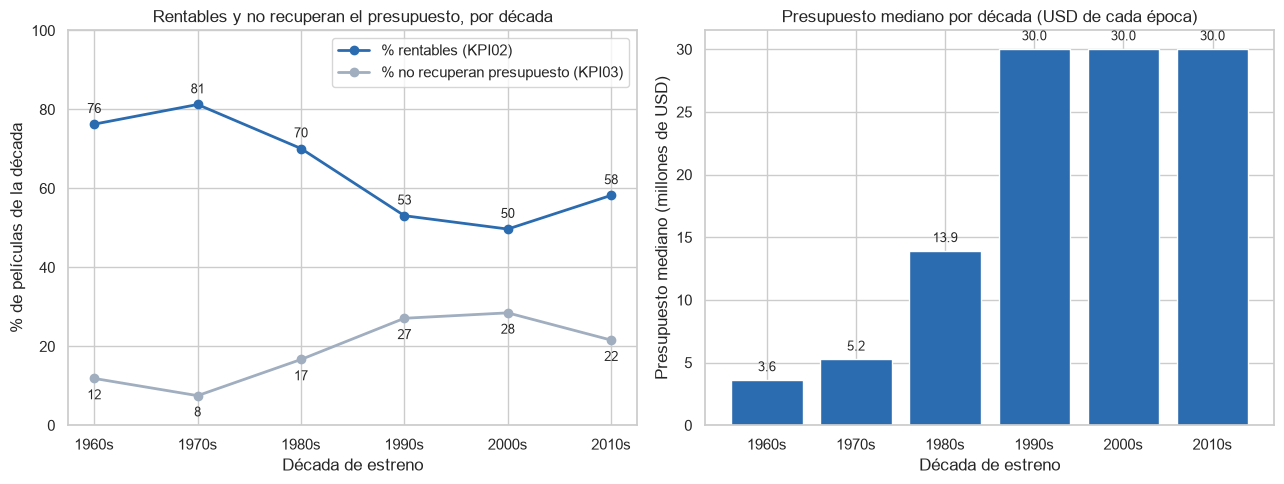

,Películas,ROI mediano (%),% rentables,% no recuperan presupuesto,Presupuesto mediano (M USD),Recaudación total (M USD),Multiplicador típico (x)
1910,1,2075.3,100.0,0.0,0.4,8.4,21.8
1920,3,1049.9,66.7,33.3,0.4,27.0,1.9
1930,12,482.9,100.0,0.0,1.5,662.8,8.6
1940,20,362.2,95.0,5.0,2.0,592.8,6.4
1950,25,464.0,96.0,4.0,2.9,383.9,4.9
1960,59,333.3,76.3,11.9,3.6,2228.6,4.7
1970,80,692.5,81.2,7.5,5.2,6428.9,8.9
1980,204,296.8,70.1,16.7,13.9,16587.8,3.4
1990,535,110.6,53.1,27.1,30.0,60946.2,1.8
2000,1324,98.2,49.7,28.5,30.0,155001.7,1.7


In [8]:
kpi_min_peliculas = 30
kpi_decada = kpi_por_segmento(kpi_base, "decada")
kpi_decada.index = kpi_decada.index.astype(int)
con_soporte = kpi_decada[kpi_decada["Películas"] >= kpi_min_peliculas]
etiquetas_decada = [f"{decada}s" for decada in con_soporte.index]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.plot(etiquetas_decada, con_soporte[kpi_columnas["KPI02"]], marker="o", linewidth=2,
         color=AZUL, label="% rentables (KPI02)")
ax1.plot(etiquetas_decada, con_soporte[kpi_columnas["KPI03"]], marker="o", linewidth=2,
         color=GRIS, label="% no recuperan presupuesto (KPI03)")
for x, (rentables, no_recuperan) in enumerate(zip(con_soporte[kpi_columnas["KPI02"]],
                                                  con_soporte[kpi_columnas["KPI03"]])):
    ax1.annotate(f"{rentables:.0f}", (x, rentables), xytext=(0, 8), textcoords="offset points",
                 ha="center", fontsize=9)
    ax1.annotate(f"{no_recuperan:.0f}", (x, no_recuperan), xytext=(0, -15), textcoords="offset points",
                 ha="center", fontsize=9)
ax1.set_ylim(0, 100)
ax1.set_title("Rentables y no recuperan el presupuesto, por década")
ax1.set_xlabel("Década de estreno")
ax1.set_ylabel("% de películas de la década")
ax1.legend(loc="upper right")

ax2.bar(etiquetas_decada, con_soporte[kpi_columnas["KPI04"]], color=AZUL)
for x, valor in enumerate(con_soporte[kpi_columnas["KPI04"]]):
    ax2.text(x, valor + 0.5, f"{valor:.1f}", ha="center", va="bottom", fontsize=9)
ax2.set_title("Presupuesto mediano por década (USD de cada época)")
ax2.set_xlabel("Década de estreno")
ax2.set_ylabel("Presupuesto mediano (millones de USD)")

plt.tight_layout()
plt.show()

kpi_decada.round(1)

**¿Qué vemos?** Desde los 70 hasta los 2000 el retorno empeora década tras década: los rentables bajan de 81 % a 50 % y las películas que no recuperan su presupuesto suben de 8 % a 28 %. Al mismo tiempo, el presupuesto mediano pasa de 5,2 a 30 millones de dólares.

Esto no quiere decir que antes fuera más fácil hacer plata con el cine. Son las dos explicaciones que ya vimos en el notebook 03: los presupuestos están en dólares de cada época, sin ajustar por inflación, y de las décadas viejas TMDB tiene sobre todo las cifras de los clásicos que funcionaron. Por eso las décadas antes de los 90 no sirven como referencia para la productora, y por eso las demás vistas usan las películas desde 2000.

Lo que sí llama la atención es que los 2010 quedan mejor que los 2000: 58,2 % de rentables contra 49,7 %, y 21,6 % que no recupera contra 28,5 %, con el mismo presupuesto mediano de 30 millones. Esa diferencia no la probamos y con estos datos no podemos explicarla. Además, la década de 2010 está incompleta: el dataset llega hasta 2017, y las películas más recientes pudieron tener menos tiempo para reportar su taquilla completa.

### 2.5 KPIs por idioma original

La sección 1.10 advierte que el inglés domina el dataset. Para no comparar idiomas con 4 o 5 películas, separamos solo inglés y el resto de idiomas juntos, y mostramos cuántos idiomas distintos hay en ese grupo.

In [9]:
kpi_idioma = {}
for periodo, datos in {"Toda la base": kpi_base, f"Desde {kpi_anio_corte}": kpi_desde_2000}.items():
    grupo_idioma = datos["original_language"].eq("en").map({True: "Inglés", False: "Otros idiomas"})
    for idioma, grupo in datos.groupby(grupo_idioma):
        kpi_idioma[(periodo, idioma)] = {**kpi_calcular(grupo),
                                         "Idiomas distintos": grupo["original_language"].nunique()}

kpi_idioma = pd.DataFrame(kpi_idioma).T.astype({"Películas": int, "Idiomas distintos": int})
kpi_idioma.round(1)

Películas  ROI mediano (%)  % rentables  \
Toda la base Inglés              3079            131.1         56.4   
             Otros idiomas        125            121.3         50.4   
Desde 2000   Inglés              2159            115.3         53.5   
             Otros idiomas        106             90.6         49.1   

                            % no recuperan presupuesto  \
Toda la base Inglés                               23.9   
             Otros idiomas                        31.2   
Desde 2000   Inglés                               25.2   
             Otros idiomas                        33.0   

                            Presupuesto mediano (M USD)  \
Toda la base Inglés                                27.0   
             Otros idiomas                          8.9   
Desde 2000   Inglés                                31.0   
             Otros idiomas                         11.0   

                            Recaudación total (M USD)  \
Toda la base Inglés                          386317.4   
             Otros idiomas                     5154.7   
Desde 2000   Inglés                          298922.5   
             Otros idiomas                     4683.3   

                            Multiplicador típico (x)  Idiomas distintos  
Toda la base Inglés                              2.1                  1  
             Otros idiomas                       1.7                 25  
Desde 2000   Inglés                              1.8                  1  
             Otros idiomas                       1.7                 23

**¿Qué vemos?** El inglés es el 95,3 % de las películas desde 2000 (2.159 de 2.265). Las otras 106 películas están repartidas en 23 idiomas, así que el grupo "Otros idiomas" mezcla cine francés, chino, español, hindi y muchos más.

Ese grupo rinde menos (49,1 % de rentables y 33,0 % que no recupera, contra 53,5 % y 25,2 % en inglés) y tiene un presupuesto mediano mucho más bajo (11 contra 31 millones). Pero no sacamos conclusiones de eso. Con tan pocas películas y tantos idiomas mezclados, no se puede separar el efecto del idioma del de ser una película pequeña, y lo más probable es que TMDB solo tenga las cifras de las películas en otros idiomas que llegaron al mercado de habla inglesa. Para la productora, el resultado práctico es otro: **los KPIs del proyecto describen sobre todo al cine en inglés**. En el dashboard el filtro de idioma tiene que mostrar siempre el número de películas, porque casi cualquier idioma distinto del inglés va a quedar con muy pocas.

### 2.6 Consistencia con las pruebas del notebook 03

Tres KPIs están hechos para seguir las hipótesis (sección 1.3). Antes de pasarlos al dashboard comprobamos que, calculados con la función de esta sección, den los mismos números que las pruebas:

- **KPI03 por cuartil de presupuesto** debería repetir el riesgo de la hipótesis 1.
- **KPI06 por temporada** debería dar el mismo cociente de la hipótesis 2: el multiplicador típico de temporada alta dividido por el del resto del año.
- **KPI02 de terror** debería dar el porcentaje de la hipótesis 3.

In [10]:
cortes = kpi_desde_2000["budget"].quantile([0, 0.25, 0.5, 0.75, 1]).to_numpy()
etiquetas_cuartil = [f"{inicio / 1e6:.0f} a {fin / 1e6:.0f} M USD" for inicio, fin in zip(cortes[:-1], cortes[1:])]
cuartil_presupuesto = pd.cut(kpi_desde_2000["budget"], cortes, labels=etiquetas_cuartil, include_lowest=True)
kpi_cuartil = kpi_por_segmento(kpi_desde_2000.assign(cuartil=cuartil_presupuesto), "cuartil")
display(kpi_cuartil[["Películas", kpi_columnas["KPI04"], kpi_columnas["KPI03"]]].round(1)
        .rename_axis(f"Cuartil de presupuesto (desde {kpi_anio_corte})"))

kpi_temporada = kpi_por_segmento(
    kpi_desde_2000.assign(temporada=kpi_desde_2000["temporada_alta"].map({True: "Temporada alta",
                                                                          False: "Resto del año"})),
    "temporada")
display(kpi_temporada.round(2).rename_axis(f"Temporada (desde {kpi_anio_corte})"))

cociente_temporada = (kpi_temporada.loc["Temporada alta", kpi_columnas["KPI06"]]
                      / kpi_temporada.loc["Resto del año", kpi_columnas["KPI06"]])
print(f"Cociente del multiplicador típico, temporada alta / resto del año: {cociente_temporada:.2f}x")
print(f"% rentables de terror desde {kpi_anio_corte}: {kpi_genero.loc['Horror', kpi_columnas['KPI02']]:.1f} %")

,Películas,Presupuesto mediano (M USD),% no recuperan presupuesto
Cuartil de presupuesto (desde 2000),,,
0 a 15 M USD,639,7.5,31.6
15 a 30 M USD,525,24.0,28.2
30 a 62 M USD,536,44.0,26.3
62 a 380 M USD,565,100.0,15.8


,Películas,ROI mediano (%),% rentables,% no recuperan presupuesto,Presupuesto mediano (M USD),Recaudación total (M USD),Multiplicador típico (x)
Temporada (desde 2000),,,,,,,
Resto del año,1173,96.90,49.62,28.82,25.0,110305.59,1.68
Temporada alta,1092,130.25,57.14,22.16,40.0,193300.16,1.95


Cociente del multiplicador típico, temporada alta / resto del año: 1.16x
% rentables de terror desde 2000: 77.6 %


**¿Qué vemos?** Los tres KPIs repiten los números del notebook 03:

- **KPI03 por cuartil:** 31,6 %, 28,2 %, 26,3 % y 15,8 % de películas que no recuperan su presupuesto, del cuartil más barato al más caro. Son los mismos de la sección 2.1 del notebook 03. Es el riesgo que el presupuesto sí cambia, aunque no cambie el retorno típico.
- **KPI06 por temporada:** 1,95x en temporada alta y 1,68x en el resto del año. El cociente da 1,16x, el mismo de la prueba de Welch de la hipótesis 2.
- **KPI02 de terror:** 77,6 %, el mismo de la hipótesis 3.

Esto importa para el dashboard: si las medidas de Power BI dan estos valores, los indicadores van a contar la misma historia que las pruebas. La tabla de temporada también deja ver por qué separamos retorno y volumen: en temporada alta la recaudación total es casi el doble (193.300 contra 110.306 millones), pero eso se explica sobre todo porque ahí salen las películas más caras (presupuesto mediano de 40 contra 25 millones). La ventaja en retorno es mucho más modesta, de 1,16x.

Una aclaración: esto es una comprobación de que los cálculos son consistentes, no una prueba nueva. La significancia de esas diferencias es la que dio cada prueba en el notebook 03; el KPI solo las sigue.

### 2.7 Tabla de referencia para Power BI

Juntamos en una sola tabla los valores que deberían dar las medidas DAX al aplicar cada filtro en el dashboard, y la guardamos en `data/processed/kpis_referencia.csv`. Cada fila dice qué vista es, qué segmento, qué periodo y cuántas películas tiene, para que al construir las medidas se pueda comparar fila por fila.

Para reproducir los filtros en el modelo del notebook 02 (sección 4):

| Filtro de la tabla | En el modelo de Power BI |
|---|---|
| Base financiera | `fact_peliculas[base_financiera] = TRUE` (siempre) |
| Desde 2000 | `dim_fecha[anio] >= 2000` |
| Género | `fact_peliculas[genero_agrupado]` |
| Década | `dim_fecha[decada]` |
| Idioma | `dim_idioma[codigo_idioma]`, inglés = `en` |
| Temporada | `dim_fecha[temporada_alta]` |

Los porcentajes de la tabla están multiplicados por 100. Como dice la sección 1.2, en Power BI se pueden dejar como fracción con formato de porcentaje; lo importante es no multiplicar dos veces.

In [11]:
periodos = {"Toda la base": kpi_base, f"Desde {kpi_anio_corte}": kpi_desde_2000}
partes = []

for periodo, tabla in kpi_general.iterrows():
    partes.append(tabla.to_frame().T.assign(vista="General", segmento="Todas", periodo=periodo))

for periodo, datos in periodos.items():
    por_genero = kpi_por_segmento(datos.dropna(subset=["genero_agrupado"]), "genero_agrupado")
    partes.append(por_genero.assign(vista="Género agrupado", segmento=por_genero.index, periodo=periodo))

    temporada = datos["temporada_alta"].map({True: "Temporada alta", False: "Resto del año"})
    por_temporada = kpi_por_segmento(datos.assign(temporada=temporada), "temporada")
    partes.append(por_temporada.assign(vista="Temporada", segmento=por_temporada.index, periodo=periodo))

    idioma = datos["original_language"].eq("en").map({True: "Inglés (en)", False: "Otros idiomas"})
    por_idioma = kpi_por_segmento(datos.assign(idioma=idioma), "idioma")
    partes.append(por_idioma.assign(vista="Idioma", segmento=por_idioma.index, periodo=periodo))

partes.append(kpi_decada.assign(vista="Década", segmento=kpi_decada.index.astype(str), periodo="Toda la base"))

kpi_referencia = (pd.concat(partes, ignore_index=True)
                  [["vista", "segmento", "periodo", "Películas", *kpi_columnas.values()]]
                  .astype({"Películas": int}))

# Cada vista debe repartir todas las películas de su periodo sin repetir ninguna
for (vista, periodo), grupo in kpi_referencia[kpi_referencia["vista"] != "General"].groupby(["vista", "periodo"]):
    esperado = len(periodos[periodo]) - (periodos[periodo]["genero_agrupado"].isna().sum()
                                         if vista == "Género agrupado" else 0)
    assert grupo["Películas"].sum() == esperado, (vista, periodo)

kpi_ruta_salida = kpi_ruta.parent / "kpis_referencia.csv"
kpi_referencia.round(4).to_csv(kpi_ruta_salida, index=False)
print(f"Archivo guardado: data/processed/{kpi_ruta_salida.name}")
print(f"Filas: {len(kpi_referencia)} | Vistas: {', '.join(kpi_referencia['vista'].unique())}")
kpi_referencia.groupby(["vista", "periodo"]).size().rename("filas").to_frame()

Archivo guardado: data/processed/kpis_referencia.csv
Filas: 45 | Vistas: General, Género agrupado, Temporada, Idioma, Década


filas
vista           periodo            
Década          Toda la base     11
General         Desde 2000        1
                Toda la base      1
Género agrupado Desde 2000       12
                Toda la base     12
Idioma          Desde 2000        2
                Toda la base      2
Temporada       Desde 2000        2
                Toda la base      2

**¿Qué vemos?** La tabla tiene 45 filas: los valores generales, los 12 géneros, las 2 temporadas y los 2 grupos de idioma, cada uno para toda la base y desde 2000, más las 11 décadas. El código comprueba que en cada vista los segmentos sumen exactamente las películas de su periodo, o sea que ninguna película se pierde ni se cuenta dos veces. La única que falta en la vista de género es la película sin género registrado, como se explicó en la sección 2.3.

Esta tabla es la que se usa en el commit de las medidas DAX: se pone el mismo filtro en Power BI y se compara el número de películas y cada KPI. Si el número de películas no coincide, el problema está en el filtro o en las relaciones del modelo, no en la medida.

### 2.8 Lo que nos dicen los KPIs

| KPI | Desde 2000 | Lo más importante para la productora |
|---|---|---|
| KPI01 ROI mediano | 115 % | Terror lo duplica (249 %); acción y drama quedan por debajo de 100 % |
| KPI02 % rentables | 53,2 % | Terror 77,6 %; los demás géneros entre 43 % y 58 %, sin diferencias probadas entre ellos |
| KPI03 % no recuperan | 25,6 % | Baja de 31,6 % a 15,8 % del cuartil de presupuesto más barato al más caro; drama y crimen llegan a una de cada tres |
| KPI04 Presupuesto mediano | 30 M USD | Terror es el único género con presupuesto mediano menor a 15 millones, y es el de mejor retorno |
| KPI05 Recaudación total | 303.606 M USD | Acción concentra casi la cuarta parte, pero rinde por debajo del total |
| KPI06 Multiplicador típico | 1,81x | 1,16 veces mayor en temporada alta, igual que en la hipótesis 2 |

Juntos, los KPIs cuentan lo mismo que las pruebas, pero con números que la productora puede seguir en el dashboard. Para una productora con capital limitado, la vista más útil es la de género: le muestra al mismo tiempo cuánto cuesta cada tipo de película, con qué frecuencia recupera el doble y con qué frecuencia no recupera nada. Y la vista por década recuerda por qué todas las comparaciones deben hacerse con el cine reciente.

Las limitaciones son las mismas de la sección 1: son montos nominales de taquilla y no utilidad neta, la base solo tiene las películas que reportaron cifras y el umbral de 2x es una aproximación. En el notebook 05 usamos estos KPIs, junto con las pruebas, para proponer las decisiones.